# Lab 4: Thermal losses of a house and a human-centred setpoint, in depth

Sheet: *Steady-State Heat Transfer Analysis, external thermal load, winter* (Q1 to Q4), then *Human-Centered AI Control and Dynamic Setpoints* (Q5 to Q9).

# Part 0: How heat leaves a house

## 0.1 The three ways heat moves

* **Conduction**: heat flows through a solid, from the hot side to the cold side. Governed by the material's **thermal conductivity** $\lambda$ [W/(m·K)]. Low $\lambda$ means a good insulator.
* **Convection**: heat is carried by moving air (or water) along a surface. Governed by a **convection coefficient** $\alpha$ [W/(m²·K)]. Wind outside makes $\alpha_E$ large (24); calm indoor air makes $\alpha_I$ smaller (8 on walls, 6 on the floor).
* **Radiation**: surfaces exchange heat as infrared light, even through empty space. Indoors this is part of why a cold window feels cold (lab 3's mean radiant temperature $t_{mr}$).

In the sheet's wall all three act in a chain: indoor air → (convection) → inner surface → (conduction through five layers) → outer surface → (convection) → outdoor air.

![Conduction, convection and radiation: the three ways heat moves](images/heat-transfer-modes.svg)

*Figure: Conduction, convection and radiation: the three ways heat moves*

![The studied ground floor: four walls, two windows, floor on the soil and a ceiling below a heated floor](images/house-envelope.svg)

*Figure: The studied ground floor: four walls, two windows, floor on the soil and a ceiling below a heated floor*

## 0.2 Thermal resistance, in series like electrical resistors

Each layer resists heat flow by $R = \delta/\lambda$ [m²K/W] ($\delta$ = thickness in metres). A convection film resists by $R = 1/\alpha$. Layers in series simply **add**, exactly like resistors in series:

$$R_{tot} = \frac{1}{\alpha_I} + \sum_i \frac{\delta_i}{\lambda_i} + \frac{1}{\alpha_E}, \qquad k = \frac{1}{R_{tot}} \quad [\text{W/(m}^2\text{K)}]$$

The **k-value** (also called U-value) is how many watts leak through each m² of wall for each kelvin of temperature difference. The steady-state heat flow is then

$$\dot Q = k \, A \, (T_I - T_E).$$

Two consequences matter for the whole lab:

* the layer with the **largest R dominates**. A 10 cm EPS layer has $R = 0.1/0.04 = 2.5$ m²K/W, more than half of the entire wall;
* the **temperature drop is proportional to R**: the insulation layer carries most of the 19 K difference (Q1 plots this).

![The five layers of the exterior wall, from outside to inside, with their thickness and conductivity](images/wall-layers.svg)

*Figure: The five layers of the exterior wall, from outside to inside, with their thickness and conductivity*

![Heat flow as an electrical network: films and layers are resistances in series](images/resistance-network.svg)

*Figure: Heat flow as an electrical network: films and layers are resistances in series*

![Thermal conductivity of building materials: concrete conducts about 80 times more than XPS](images/conductivity-scale.svg)

*Figure: Thermal conductivity of building materials: concrete conducts about 80 times more than XPS*

## 0.3 Windows: they lose heat, but the sun gives some back

A window has a high k-value (2.56 W/m²K, about 12 times the wall) so it loses a lot per m². But glass lets solar radiation in. The sheet's balance for one window is

$$\dot Q_{window} = -\,c_1 c_2 c_3\, m\, A\, I_T \;+\; k_{GS}\, A\,(T_I - T_E)$$

with $c_1 = 0.9$ (double glazing), $c_2 = 0.6$ (light blinds), $c_3 = 0.6$ (metallic frame), $m$ = a window-orientation factor (0.3 east, 0.7 south) and $I_T$ = solar irradiance on the vertical surface (55 W/m² east, 380 W/m² south, at noon). A **negative** result means the window gives net heat to the room.

![A window loses heat by conduction and gains heat from the sun: the balance can be negative](images/window-heat-balance.svg)

*Figure: A window loses heat by conduction and gains heat from the sun: the balance can be negative*

## 0.4 The floor and the ground

The ground floor sits on gravel and soil. Heat flows downward through hardwood, screed, XPS insulation, concrete, gravel and then **7 m of soil** (treated as two soil layers) until it reaches the deep soil temperature (about 11 °C, the sheet suggests 10 to 12 °C). Soil is a poor insulator but 7 m of it is a lot of resistance, so the floor loss is small. The ceiling touches another heated floor at the same 24 °C, so $T_I - T_{above} = 0$ and **no heat flows through it**.

![Heat flowing down through the floor layers and 7 m of soil to the deep ground temperature](images/floor-to-soil.svg)

*Figure: Heat flowing down through the floor layers and 7 m of soil to the deep ground temperature*

## 0.5 From heat load to electricity

The studied radiator is an **electric resistance** heater: every watt of electricity becomes one watt of heat (efficiency 1). So a heat load of 363 W needs 363 W of electricity, which over one hour is 0.363 kWh. A heat pump with a COP of 3 would need only a third of that.

## 0.6 The link to lab 3

Lab 3 asked: what is the **lowest air temperature** that still keeps $-0.5 \le PMV \le 0.5$? Here we take that answer and ask: **how much energy does the lower setpoint save?** The chain is

comfort model (PMV) → lowest comfortable $t_I$ → heat load at that $t_I$ → electricity saved.

![The human-centred chain: occupant data, PMV, optimal setpoint, heat load, energy saved](images/ai-setpoint-chain.svg)

*Figure: The human-centred chain: occupant data, PMV, optimal setpoint, heat load, energy saved*

In [1]:
import sys; sys.path.insert(0, "../shared")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from heat_loss import *

plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.grid": True, "grid.alpha": .3})

**Data from the sheet.** Resistance $R = \delta/\lambda$ of every layer (wall from outside to inside, floor from inside to deep soil).

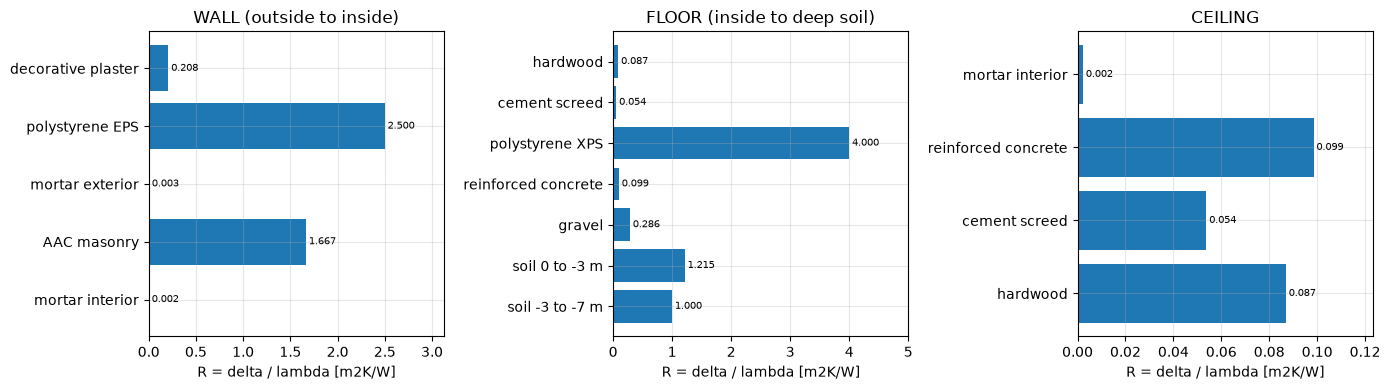

T_E = 5.0 C, T_I = 24.0 C, T_soil = 11.0 C; alpha_E = 24.0, alpha_I wall = 8.0, alpha_I floor = 6.0 W/m2K
wall area gross 72 m2, windows 4.0 m2, net opaque 68.0 m2, floor 36.0 m2


In [2]:
fig_, ax = plt.subplots(1, 3, figsize=(14, 4))
for a_, (name, layers) in zip(ax, (("WALL (outside to inside)", WALL), ("FLOOR (inside to deep soil)", FLOOR), ("CEILING", CEILING))):
    t = layer_table(layers)
    bars = a_.barh(t.layer[::-1], t.R_m2K_W[::-1], color="tab:blue")
    a_.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
    a_.set(title=name, xlabel="R = delta / lambda [m2K/W]"); a_.margins(x=0.25)
plt.tight_layout(); plt.show()
print(f"T_E = {T_E} C, T_I = {T_I} C, T_soil = {T_SOIL} C; alpha_E = {ALPHA_E}, alpha_I wall = {ALPHA_I_WALL}, alpha_I floor = {ALPHA_I_FLOOR} W/m2K")
print(f"wall area gross {A_WALL_GROSS} m2, windows {A_WIN_EAST + A_WIN_SOUTH} m2, net opaque {A_WALL_GROSS - A_WIN_EAST - A_WIN_SOUTH} m2, floor {A_FLOOR} m2")

**Interpretation of the data.** The EPS layer ($R=2.5$ m²K/W) and the AAC layer ($R=1.67$) make up almost the whole wall resistance; plasters and mortars are thin and conduct relatively well, so they hardly matter. In the floor the XPS layer ($R=4.0$) and the two soil layers (1.2 and 1.0) dominate. The ceiling is the opposite, a thin conductive stack ($k \approx 2.45$ W/m²K), which is fine only because there is no temperature difference across it.

# Q1: Heat flux density through the wall

**Task.** Surface heat-transfer density through the exterior wall with $t_I = 24$ °C and $t_E = 5$ °C.

**Method.** Sum the resistances in series, invert for $k$, multiply by the temperature difference: $q = k\,(T_I - T_E)$.

In [3]:
r_tot = total_resistance(WALL, ALPHA_I_WALL, ALPHA_E)
k_w = k_value(WALL, ALPHA_I_WALL, ALPHA_E)
q = wall_flux()
print(f"R_total = {r_tot:.4f} m2K/W")
print(f"k       = {k_w:.4f} W/(m2K)")
print(f"q       = {q:.3f} W/m2   (T_I - T_E = {T_I - T_E:.0f} K)")

R_total = 4.5474 m2K/W
k       = 0.2199 W/(m2K)
q       = 4.178 W/m2   (T_I - T_E = 19 K)


## Hand calculation Q1

Resistances (m²K/W):

* inner film $1/8 = 0.1250$; outer film $1/24 = 0.0417$
* decorative plaster $0.005/0.024 = 0.2083$; EPS $0.100/0.040 = 2.5000$; outer mortar $0.003/0.87 = 0.0034$; AAC $0.250/0.15 = 1.6667$; inner mortar $0.002/0.87 = 0.0023$

Conduction sum: $0.2083 + 2.5000 + 0.0034 + 1.6667 + 0.0023 = 4.3807$.
Total: $R_{tot} = 0.1250 + 4.3807 + 0.0417 = 4.5474$ m²K/W, so $k = 1/4.5474 = 0.2199$ W/m²K.

Flux: $q = 0.2199 \times (24 - 5) = 0.2199 \times 19 = 4.18$ W/m².

**Temperature profile.** With the flux known, the temperature falls across each layer by $\Delta T = q\,R_{layer}$. The plot shows the temperature through the wall from the indoor air (left) to the outdoor air (right).

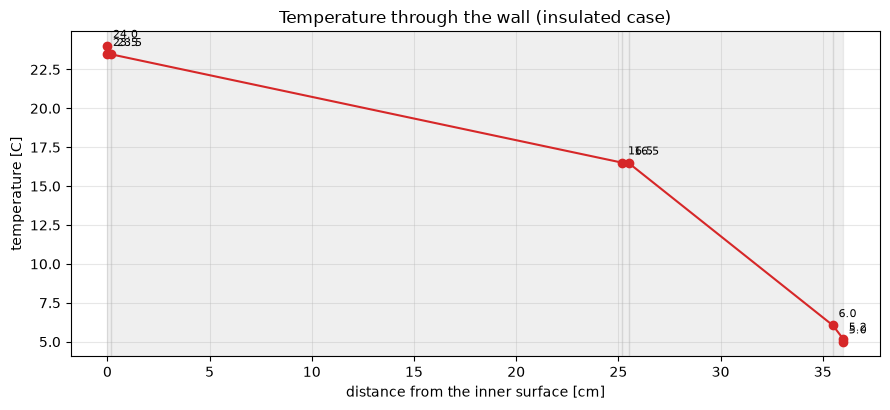

In [4]:
prof = temperature_profile(WALL, ALPHA_I_WALL, ALPHA_E, T_I, T_E)
lay = layer_table(WALL).iloc[::-1]
x = [0, 0] + list(np.cumsum(lay.delta_m * 100)) + [lay.delta_m.sum() * 100]   # cm, films have zero thickness here
fig_, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(x, prof.temp, "o-", color="tab:red")
for xi, ti, name in zip(x, prof.temp, prof.point):
    ax.annotate(f"{ti:.1f}", (xi, ti), textcoords="offset points", xytext=(4, 6), fontsize=8)
bounds = np.concatenate([[0], np.cumsum(lay.delta_m * 100)])
for (a, b), n in zip(zip(bounds[:-1], bounds[1:]), lay.layer):
    ax.axvspan(a, b, color="grey", alpha=.12)
ax.set(xlabel="distance from the inner surface [cm]", ylabel="temperature [C]", title="Temperature through the wall (insulated case)")
plt.tight_layout(); plt.show()

### Interpretation of Q1

* **Flux:** about **4.18 W/m²** leave through the wall, which is tiny compared with a bare wall (9.28 W/m² in Q2b). The wall's k is only **0.220 W/m²K**: a good, modern value.
* **Where the drop happens:** the air-to-surface films barely change the temperature (24.0 to 23.5 °C inside, 5.2 to 5.0 °C outside) because their resistances are small. Almost the whole 19 K falls across the **EPS layer (about 10.5 K, 16.5 to 6.0 °C)** and the **AAC block (about 7.0 K, 23.5 to 16.5 °C)**. This is the picture of "the largest R dominates".
* **Why it matters for comfort:** the inner surface stays at 23.5 °C, only 0.5 K below the air. A well-insulated wall hardly lowers the mean radiant temperature. In lab 3, a cold wall lowered $t_{mr}$; here the walls are not the problem, the windows are.

# Q2: Hourly electricity of the radiator, with and without insulation

**Task.** The four walls are identical (6 m × 3 m each) and all see the same flux. Compute the hourly electricity consumption of the radiator for the ground floor in two cases: (a) the wall as given, (b) the wall without the EPS layer.

**Method.** Add every part of the envelope: opaque wall (net area = gross minus the windows), the east and south windows (with solar gain), the floor to the soil, and the ceiling (zero). One hour at constant power gives kWh = W / 1000.

(a) k = 0.2199 W/m2K, flux = 4.18 W/m2
(b) k = 0.4884 W/m2K, flux = 9.28 W/m2
(a) electricity in one hour = 0.363 kWh
(b) electricity in one hour = 0.710 kWh
wall share of the total: (a) 78 %, (b) 89 %
EPS saves 347 W = 49 % of the load without it


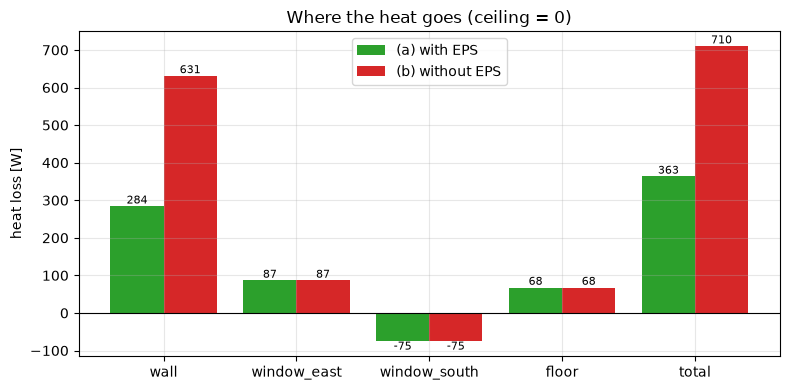

In [5]:
nw = without_layer(WALL, "polystyrene EPS")
a, b = total_load(), total_load(wall_layers=nw)
print(f"(a) k = {k_value(WALL, ALPHA_I_WALL, ALPHA_E):.4f} W/m2K, flux = {wall_flux():.2f} W/m2")
print(f"(b) k = {k_value(nw, ALPHA_I_WALL, ALPHA_E):.4f} W/m2K, flux = {wall_flux(layers=nw):.2f} W/m2")
print(f"(a) electricity in one hour = {electricity_kwh(a['total']):.3f} kWh")
print(f"(b) electricity in one hour = {electricity_kwh(b['total']):.3f} kWh")
print(f"wall share of the total: (a) {100 * a['wall'] / a['total']:.0f} %, (b) {100 * b['wall'] / b['total']:.0f} %")
print(f"EPS saves {b['total'] - a['total']:.0f} W = {100 * (b['total'] - a['total']) / b['total']:.0f} % of the load without it")

parts = ["wall", "window_east", "window_south", "floor", "total"]
fig_, ax = plt.subplots(figsize=(8, 4))
xs = np.arange(len(parts))
b1 = ax.bar(xs - 0.2, [a[p] for p in parts], 0.4, label="(a) with EPS", color="tab:green")
b2 = ax.bar(xs + 0.2, [b[p] for p in parts], 0.4, label="(b) without EPS", color="tab:red")
ax.bar_label(b1, fmt="%.0f", fontsize=8); ax.bar_label(b2, fmt="%.0f", fontsize=8)
ax.axhline(0, color="k", lw=.8)
ax.set_xticks(xs); ax.set_xticklabels(parts); ax.set(ylabel="heat loss [W]", title="Where the heat goes (ceiling = 0)"); ax.legend()
plt.tight_layout(); plt.show()

## Hand calculation Q2

Net opaque wall area: $4 \times (3 \times 6) - 2 - 2 = 72 - 4 = 68$ m².

* **Wall (a):** $4.178 \times 68 = 284.1$ W. **Wall (b):** $k = 1/(0.1250 + 1.8807 + 0.0417) = 0.4884$, $q = 0.4884 \times 19 = 9.28$ W/m², $9.28 \times 68 = 631.0$ W.
* **East window:** solar $-0.9 \times 0.6 \times 0.6 \times 0.3 \times 2 \times 55 = -10.7$ W; conduction $2.56 \times 2 \times 19 = 97.3$ W; net **+86.6 W**.
* **South window:** solar $-0.324 \times 0.7 \times 2 \times 380 = -172.4$ W; conduction $97.3$ W; net **-75.1 W** (a net gain).
* **Floor:** $R_{tot} = 1/6 + 0.0870 + 0.0538 + 4.0000 + 0.0985 + 0.2857 + 1.2150 + 1.0000 = 6.9067$, $k = 0.1448$; $\Delta T = 24 - 11 = 13$ K; $0.1448 \times 36 \times 13 = 67.8$ W.
* **Ceiling:** $\Delta T = 24 - 24 = 0$, so 0 W.

Total (a): $284.1 + 86.6 - 75.1 + 67.8 + 0 = 363.4$ W, i.e. $0.363$ kWh in one hour.
Total (b): $631.0 + 86.6 - 75.1 + 67.8 + 0 = 710.3$ W, i.e. $0.710$ kWh in one hour.

### Interpretation of Q2

* **Answer:** with the 10 cm EPS layer the radiator needs **363 W**, i.e. **0.363 kWh per hour**. Without it the need is **710 W = 0.710 kWh per hour**, almost exactly double.
* **EPS saves 347 W (49 %)** of the uninsulated load. Spread over a heating season (hundreds of hours) this is a large amount of electricity for a cheap layer.
* **The wall dominates:** it is 78 % of the load with EPS and 89 % without. That is why insulation of the opaque wall is the first measure to look at.
* **The south window is a net heater at noon:** its solar gain (172 W) exceeds its conduction loss (97 W), giving -75 W. The east window, with weak winter sun (55 W/m²), is a net loss (+87 W). The windows together have a small net effect (+11.5 W), but only because it is noon; at night both are pure losses.
* **The floor loses little (68 W)** thanks to the XPS layer and the thick soil, and **the ceiling loses nothing** because the room above is at the same temperature.
* **Caveat:** this is one steady-state hour at noon, with no infiltration and no thermal inertia, exactly as the sheet says. A real day has no solar gain at night, so the average load would be higher.

# Q3: Effect of the insulation thickness

**Task.** What effect does the thickness of the EPS layer have on heat loss and on electricity consumption?

first 5 cm of EPS saves    239.2 W
5 to 10 cm saves           107.7 W
10 to 15 cm saves           61.3 W
15 to 20 cm saves           39.5 W


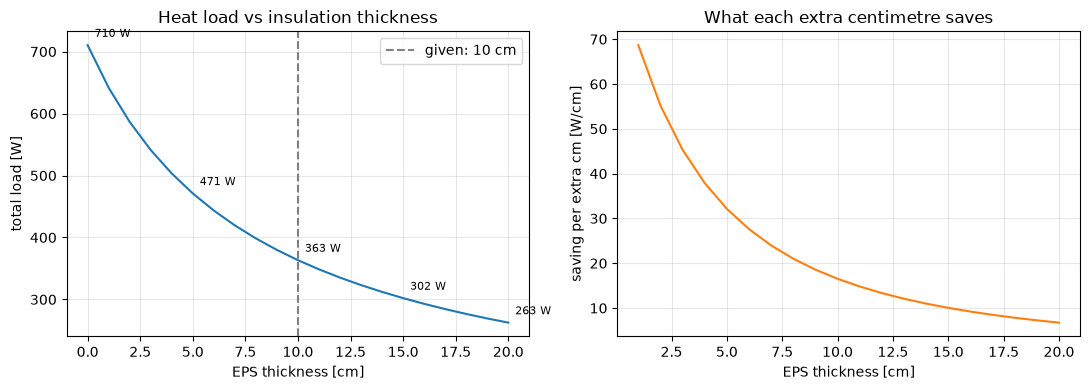

In [6]:
sweep = insulation_sweep(np.linspace(0, 0.20, 21))
at = sweep.set_index(sweep.eps_m.round(2)).load_W
print(f"first 5 cm of EPS saves   {at[0.00] - at[0.05]:6.1f} W")
print(f"5 to 10 cm saves          {at[0.05] - at[0.10]:6.1f} W")
print(f"10 to 15 cm saves         {at[0.10] - at[0.15]:6.1f} W")
print(f"15 to 20 cm saves         {at[0.15] - at[0.20]:6.1f} W")

fig_, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sweep.eps_m * 100, sweep.load_W, color="tab:blue")
ax[0].axvline(10, color="grey", ls="--", label="given: 10 cm"); ax[0].legend()
for cm in (0, 5, 10, 15, 20): ax[0].annotate(f"{at[round(cm / 100, 2)]:.0f} W", (cm, at[round(cm / 100, 2)]), textcoords="offset points", xytext=(5, 6), fontsize=8)
ax[0].set(xlabel="EPS thickness [cm]", ylabel="total load [W]", title="Heat load vs insulation thickness")
ax[1].plot(sweep.eps_m[1:] * 100, -np.diff(sweep.load_W) / (np.diff(sweep.eps_m) * 100), color="tab:orange")
ax[1].set(xlabel="EPS thickness [cm]", ylabel="saving per extra cm [W/cm]", title="What each extra centimetre saves")
plt.tight_layout(); plt.show()

### Interpretation of Q3

* **The load falls fast, then slowly (diminishing returns).** Going from 0 to 5 cm saves **239 W**; 5 to 10 cm saves 108 W; 10 to 15 cm saves 61 W; 15 to 20 cm saves only **40 W**. The right-hand plot shows the saving per extra centimetre dropping steadily.
* **Why:** the load follows $k \propto 1/(R_0 + d/\lambda)$. Each added layer increases R by the same amount, but the *relative* increase of the total R gets smaller. Doubling a thin layer changes a lot; doubling a thick one hardly matters.
* **The given 10 cm is a sensible point:** at 10 cm the load is 363 W (0.363 kWh/h), already 49 % below no insulation. Doubling to 20 cm gives 263 W (0.263 kWh/h), a further 100 W for twice the material, so the choice then becomes a cost question (price per cm against saved kWh over the building's life), which the sheet does not give.
* **Electricity follows heat loss one to one** (efficiency 1), so the electricity (kWh) falls in the same proportion as the load.

# Q4: Comparing materials and choosing the optimal combination

**Task.** With the listed materials (cement plaster 0.80, reinforced concrete 2.03, solid brick 0.70, hollow brick 0.35, AAC 0.15, mineral wool 0.036, EPS 0.04, XPS 0.025 W/mK), pick the best wall.

**Method.** Build every wall from the same pattern: cement plaster (0.5 cm) outside, an insulation layer (10 cm), a structural layer (25 cm) and cement plaster (0.5 cm) inside. That gives 4 structures × 3 insulations = 12 walls of equal 36 cm thickness, so they are compared fairly. Rank by $k$ (lowest is best).

given wall: k = 0.220
best      : AAC + polystyrene XPS, k = 0.171, flux = 3.25 W/m2
best wall load 221 W vs given 284 W, saving 63 W (22 %)


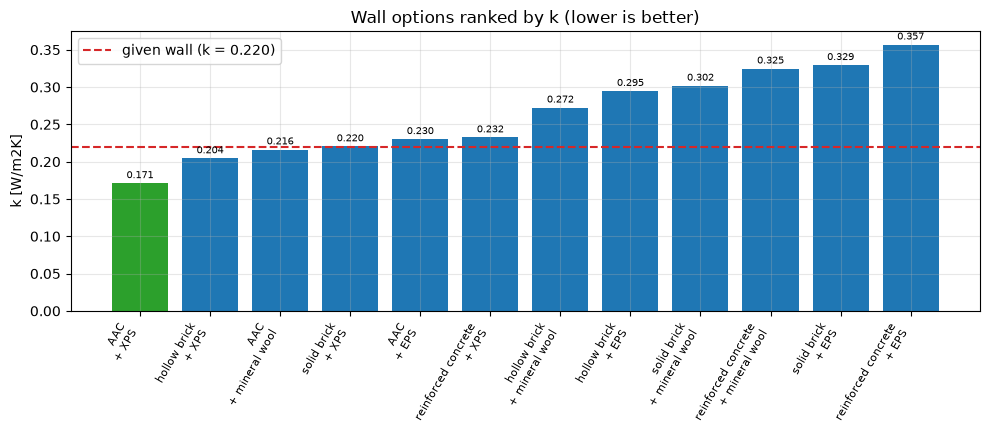


mean k by insulation : {'mineral wool': 0.279, 'polystyrene EPS': 0.303, 'polystyrene XPS': 0.207}
mean k by structure  : {'AAC': 0.206, 'hollow brick': 0.257, 'reinforced concrete': 0.305, 'solid brick': 0.284}


In [7]:
opts = wall_options()
k_given = k_value(WALL, ALPHA_I_WALL, ALPHA_E)
a_net = A_WALL_GROSS - A_WIN_EAST - A_WIN_SOUTH
best = opts.iloc[0]
print(f"given wall: k = {k_given:.3f}")
print(f"best      : {best.structure} + {best.insulation}, k = {best.k_wall:.3f}, flux = {best.flux_W_m2:.2f} W/m2")
print(f"best wall load {best.flux_W_m2 * a_net:.0f} W vs given {wall_flux() * a_net:.0f} W, saving {wall_flux() * a_net - best.flux_W_m2 * a_net:.0f} W ({100 * (1 - best.k_wall / k_given):.0f} %)")

labels = opts.structure + "\n+ " + opts.insulation.str.replace("polystyrene ", "")
fig_, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(range(len(opts)), opts.k_wall, color=["tab:green" if i == 0 else "tab:blue" for i in range(len(opts))])
ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
ax.axhline(k_given, color="tab:red", ls="--", label=f"given wall (k = {k_given:.3f})")
ax.set_xticks(range(len(opts))); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
ax.set(ylabel="k [W/m2K]", title="Wall options ranked by k (lower is better)"); ax.legend()
plt.tight_layout(); plt.show()

print()
print("mean k by insulation :", opts.groupby("insulation").k_wall.mean().round(3).to_dict())
print("mean k by structure  :", opts.groupby("structure").k_wall.mean().round(3).to_dict())

### Interpretation of Q4

* **Best combination: AAC + XPS** with $k = 0.171$ W/m²K and a flux of 3.25 W/m². It beats the given wall (k = 0.220) by **22 %**, saving about **63 W** on the 68 m² of wall. It is the lowest-conductivity pair in each category (AAC 0.15 W/mK for the structure, XPS 0.025 for the insulation), so there is no trade-off in the ranking.
* **Both choices matter about equally:** the mean k over the four structures is 0.207 for XPS, 0.279 for mineral wool and 0.303 for EPS (a spread of 0.096), and over the three insulations it is 0.206 for AAC, 0.257 for hollow brick, 0.284 for solid brick and 0.305 for reinforced concrete (a spread of 0.099). A good result needs both a low-conductivity block and a low-conductivity insulation.
* **Reinforced concrete is a poor wall material thermally (2.03 W/mK):** with EPS it is the worst (k = 0.357); even its best combination (with XPS, k = 0.232) is worse than the given wall.
* **Ranking surprises:** hollow brick + XPS (0.204) beats solid brick + XPS (0.220), and AAC + mineral wool (0.216) beats AAC + EPS (0.230) because mineral wool ($\lambda = 0.036$) is slightly better than EPS (0.040).
* **Practical caveats the numbers do not show.** Cost is not given, and XPS is usually the most expensive insulation. Mineral wool is non-combustible (a big advantage for fire safety) and vapour-open, but loses its insulating power if it gets wet. XPS resists moisture, which is why the sheet uses it below ground. AAC is light and easy to cut but fragile and must be protected against moisture. So **AAC + XPS is optimal for heat loss alone**; a real design would also weigh price, fire rules and moisture.

# Q5 to Q9: Human-centred control and dynamic setpoints

**The idea.** Q1 to Q4 assumed a rigid indoor temperature of 24 °C. But a person in a winter sweater (clo = 1.0) is comfortable at a lower air temperature (lab 3). So instead of a fixed number, an "AI agent" computes the **lowest air temperature with PMV ≥ -0.5** and the heating follows that.

**Conditions from the sheet:** clo = 1.0, RH = 40 %, air speed 0.1 m/s, $t_{mr} = t_a - 2$. The sheet's notes say **MET = 1.1** but its starter code says **MET = 1.2**, so both are computed.

MET 1.1: PMV at 24 C = +0.130; optimal setpoint 21.34 C (PMV -0.500); load 363 -> 282 W (0.363 -> 0.282 kWh in one hour); saving 81 W = 22.3 %, 30.4 W per K
MET 1.2: PMV at 24 C = +0.305; optimal setpoint 20.23 C (PMV -0.500); load 363 -> 249 W (0.363 -> 0.249 kWh in one hour); saving 115 W = 31.6 %, 30.4 W per K


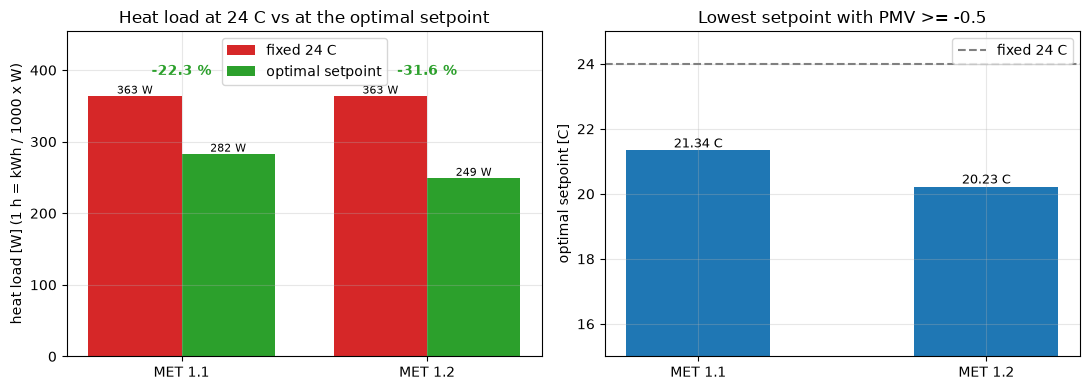

In [8]:
rows = []
for met in (1.1, 1.2):
    t_opt = optimal_setpoint(clo=1.0, met=met, rh=40, v=0.1, tmr_offset=-2.0)
    s = savings(t_opt)
    rows.append(dict(met=met, pmv_at_24=pmv(24, 22, 0.1, 40, 1.0, met), t_opt=t_opt, pmv_at_opt=pmv(t_opt, t_opt - 2, 0.1, 40, 1.0, met),
                     load_24_W=s["load_fixed"], load_opt_W=s["load_opt"], kWh_24=s["kwh_fixed"], kWh_opt=s["kwh_opt"],
                     saving_W=s["saving_W"], saving_pct=s["saving_pct"], W_per_K=s["saving_W"] / (24 - t_opt)))
res = pd.DataFrame(rows).set_index("met")
for met, r in res.iterrows():
    print(f"MET {met}: PMV at 24 C = {r.pmv_at_24:+.3f}; optimal setpoint {r.t_opt:.2f} C (PMV {r.pmv_at_opt:+.3f}); "
          f"load {r.load_24_W:.0f} -> {r.load_opt_W:.0f} W ({r.kWh_24:.3f} -> {r.kWh_opt:.3f} kWh in one hour); "
          f"saving {r.saving_W:.0f} W = {r.saving_pct:.1f} %, {r.W_per_K:.1f} W per K")
fig_, ax = plt.subplots(1, 2, figsize=(11, 4))
xs, w = np.arange(len(res)), 0.38
b1 = ax[0].bar(xs - w / 2, res.load_24_W, w, color="tab:red", label="fixed 24 C")
b2 = ax[0].bar(xs + w / 2, res.load_opt_W, w, color="tab:green", label="optimal setpoint")
ax[0].bar_label(b1, fmt="%.0f W", fontsize=8); ax[0].bar_label(b2, fmt="%.0f W", fontsize=8)
for i, p in enumerate(res.saving_pct): ax[0].text(i, res.load_24_W.iloc[i] + 30, f"-{p:.1f} %", ha="center", fontweight="bold", color="tab:green")
ax[0].set_xticks(xs); ax[0].set_xticklabels([f"MET {m}" for m in res.index]); ax[0].set_ylim(0, res.load_24_W.max() * 1.25)
ax[0].set(ylabel="heat load [W] (1 h = kWh / 1000 x W)", title="Heat load at 24 C vs at the optimal setpoint"); ax[0].legend()
b3 = ax[1].bar(xs, res.t_opt, 0.5, color="tab:blue")
ax[1].bar_label(b3, fmt="%.2f C", fontsize=9); ax[1].axhline(24, color="grey", ls="--", label="fixed 24 C")
ax[1].set_xticks(xs); ax[1].set_xticklabels([f"MET {m}" for m in res.index]); ax[1].set_ylim(15, 25)
ax[1].set(ylabel="optimal setpoint [C]", title="Lowest setpoint with PMV >= -0.5"); ax[1].legend()
plt.tight_layout(); plt.show()

### Interpretation of Q5 to Q8

* **The optimal setpoints:** **20.23 °C** with MET = 1.2 and **21.34 °C** with MET = 1.1. A lower metabolic rate means the body makes less heat, so the air must stay warmer. A 0.1 met difference moves the setpoint by 1.1 K.
* **24 °C is already slightly warm for this occupant:** at 24 °C the PMV is +0.305 (MET = 1.2) or +0.130 (MET = 1.1). The fixed 24 °C is not just wasteful, it is not even the most comfortable choice for someone in a sweater.
* **Energy saved (Q8):** the load drops from 363 W (0.363 kWh in one hour) to **249 W (0.249 kWh)** at MET = 1.2, a **115 W or 31.6 %** saving. With MET = 1.1 it drops to 282 W, a **81 W or 22.3 %** saving.
* **Every kelvin is worth about 30 W** (30.4 W/K in both cases): this is about 8 % of the 24 °C load per kelvin of setpoint reduction. The relation is linear, so the saving is simply 30.4 W times the degrees lowered.

## Why the saving is bigger than the sheet's "10 to 15 %"

The sheet says a reduction of a few °C often saves 10 to 15 % of the heating load. Our 22 to 32 % is larger, for two reasons that the next cell makes visible. First, the temperature difference to the outside is not the same everywhere: the wall and windows lose in proportion to $t_I - 5$ (19 K down to 15.2 K, a 20 % drop), the floor in proportion to $t_I - 11$ (13 K down to 9.2 K, a 29 % drop). Second, the **solar gain of the windows (183 W) is a fixed offset** that does not shrink when the setpoint falls. The conduction losses fall by 21 %, but they are reduced from a smaller base (546 W gross, 363 W net after the sun), so the *net* load falls by a larger percentage.

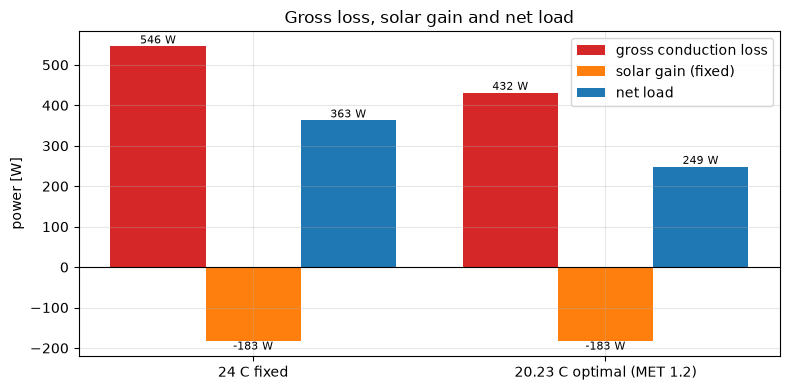

gross conduction loss falls by 21.0 %, net load falls by 31.6 %


In [9]:
solar = sum(C1 * C2 * C3 * w["m"] * w["area"] * w["i_t"] for w in WINDOWS.values())
t12 = optimal_setpoint(met=1.2)
rows = []
for label, t in (("24 C fixed", 24.0), (f"{t12:.2f} C optimal (MET 1.2)", t12)):
    net = total_load(t)["total"]
    rows.append({"setpoint": label, "gross conduction loss [W]": net + solar, "solar gain [W]": -solar, "net load [W]": net})
dec = pd.DataFrame(rows).set_index("setpoint")
fig_, ax = plt.subplots(figsize=(8, 4))
xs, w = np.arange(len(dec)), 0.27
for k_, (col, color, lab) in enumerate((("gross conduction loss [W]", "tab:red", "gross conduction loss"),
                                        ("solar gain [W]", "tab:orange", "solar gain (fixed)"),
                                        ("net load [W]", "tab:blue", "net load"))):
    bars = ax.bar(xs + (k_ - 1) * w, dec[col], w, color=color, label=lab)
    ax.bar_label(bars, fmt="%.0f W", fontsize=8)
ax.axhline(0, color="k", lw=.8); ax.set_xticks(xs); ax.set_xticklabels(dec.index)
ax.set(ylabel="power [W]", title="Gross loss, solar gain and net load"); ax.legend()
plt.tight_layout(); plt.show()
drop_gross = 100 * (1 - dec.iloc[1, 0] / dec.iloc[0, 0]); drop_net = 100 * (1 - dec.iloc[1, 2] / dec.iloc[0, 2])
print(f"gross conduction loss falls by {drop_gross:.1f} %, net load falls by {drop_net:.1f} %")

### Interpretation of the decomposition

* **Gross conduction loss** (everything leaving through the envelope) falls from **546 W to 432 W, -21 %**. This is already above the "10 to 15 %" rule of thumb, because 3.8 K is more than "a few" degrees: at 30.4 W/K a 2 K reduction saves 61 W, which is 11 % of 546 W, right inside the sheet's range.
* **The sun's 183 W does not change**, so the *net* load falls from 363 W to 249 W, **-31.6 %**. The same absolute saving (115 W) looks bigger as a percentage of the smaller net load.
* **So both statements are true:** the sheet's 10 to 15 % is typical for a reduction of about 2 K; our 3.8 K reduction gives 21 % even on the gross loss, and the noon sun on the south window lifts the net figure to 31.6 %. On a cloudy day or at night the percentage would be the 21 % gross value.

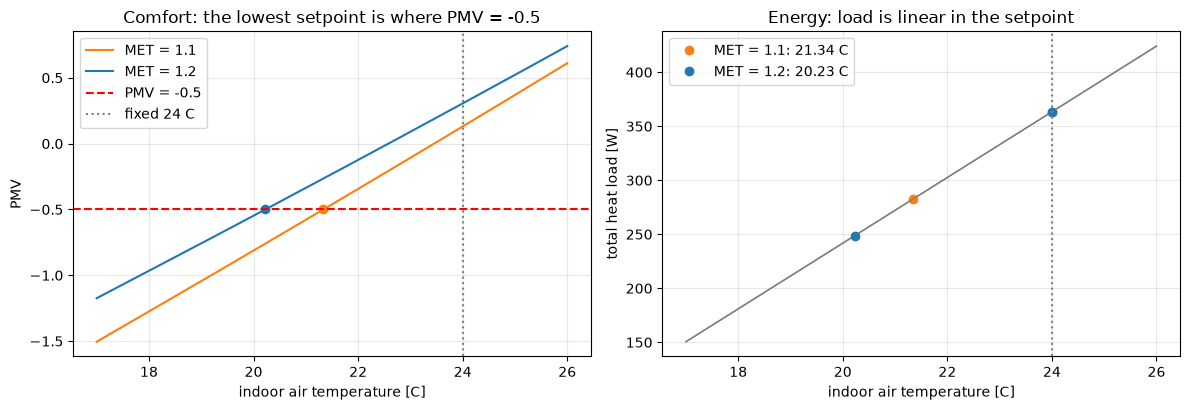

In [10]:
ta = np.linspace(17, 26, 181)
fig_, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for met, col in ((1.1, "tab:orange"), (1.2, "tab:blue")):
    ax[0].plot(ta, [pmv(t, t - 2, 0.1, 40, 1.0, met) for t in ta], color=col, label=f"MET = {met}")
    t_opt = res.loc[met, "t_opt"]
    ax[0].plot(t_opt, -0.5, "o", color=col)
    ax[1].plot(ta, [total_load(t)["total"] for t in ta], color="tab:grey", lw=1)
    ax[1].plot([24, t_opt], [total_load(24)["total"], total_load(t_opt)["total"]], "o", color=col, label=f"MET = {met}: {t_opt:.2f} C")
ax[0].axhline(-0.5, color="red", ls="--", label="PMV = -0.5"); ax[0].axvline(24, color="grey", ls=":", label="fixed 24 C")
ax[0].set(xlabel="indoor air temperature [C]", ylabel="PMV", title="Comfort: the lowest setpoint is where PMV = -0.5"); ax[0].legend()
ax[1].axvline(24, color="grey", ls=":")
ax[1].set(xlabel="indoor air temperature [C]", ylabel="total heat load [W]", title="Energy: load is linear in the setpoint"); ax[1].legend()
plt.tight_layout(); plt.show()

### Interpretation of the plots

* **Left:** the PMV curve rises with temperature; its crossing with the red line (-0.5) is the optimal setpoint. The MET = 1.1 curve lies below the MET = 1.2 curve, so it crosses later (21.3 °C against 20.2 °C).
* **Right:** the load is a straight line in the setpoint (slope about 30 W/K), so every degree the agent saves is worth the same. The dots are the two optima against the fixed 24 °C.

## The t_mr = t_a - 2 assumption and the limits of this analysis

In [11]:
for t in (24.0, t12):
    inner = temperature_profile(WALL, ALPHA_I_WALL, ALPHA_E, t, T_E).temp[1]
    print(f"setpoint {t:5.2f} C: wall inner surface {inner:5.2f} C ({t - inner:.2f} K below the air)")

setpoint 24.00 C: wall inner surface 23.48 C (0.52 K below the air)
setpoint 20.23 C: wall inner surface 19.81 C (0.42 K below the air)


### Interpretation: how reliable is this?

* **The assumption is conservative.** The sheet sets $t_{mr} = t_a - 2$. For the insulated wall the inner surface is only 0.52 K below the air at 24 °C (and 0.42 K below at 20.2 °C). The windows are colder, but together with the warm walls and floor the true mean radiant temperature is probably closer to the air temperature than 2 K below. If $t_{mr}$ were higher, the optimal setpoint would be even lower and the saving larger. The sheet's value is a safe estimate.
* **Steady state at noon.** The calculation uses one hour of data at noon, ignores thermal inertia and infiltration, and counts the full solar gain. At night, with no sun, the optimal setpoint is unchanged (it depends only on comfort) and the absolute saving is the same 115 W, but as a share of the larger night load (546 W) it is 21 %.
* **The core lesson of the sheet holds:** lowering the setpoint by a few kelvin because the person wears a sweater saves roughly **a quarter to a third of the electricity** here, at **no loss of comfort** (PMV stays at the acceptable limit -0.5), simply because the controller uses a human comfort model instead of a fixed number.

# Summary

* **Q1**: k = 0.220 W/m²K, flux 4.18 W/m². The insulation layer carries most of the 19 K drop
* **Q2**: 363 W (0.363 kWh/h) with EPS, 710 W (0.710 kWh/h) without. EPS halves the load; the south window is a net heater at noon
* **Q3**: first 5 cm saves 239 W, last 5 cm only 40 W. Diminishing returns; 10 cm is a sensible point
* **Q4**: AAC + XPS, k = 0.171 (22 % better than the given wall). Insulation matters more than structure; check cost, fire and moisture
* **Q5 to Q8**: optimal setpoint 20.2 °C (MET 1.2) or 21.3 °C (MET 1.1). 24 °C is already slightly warm for a person in a sweater
* **Q8**: 115 W (31.6 %) or 81 W (22.3 %) saved. About 30 W per kelvin
* **Q9**: more than the sheet's 10 to 15 %. The fixed solar gain makes the net percentage larger